
=== Starting Fully Online Continuous Learning ===
Step 0, Current_State: (0, 0, 0, 0, 0, 0, 0), New_State: (0, 0, 0, 0, 0, 0, 0), Reward: -0.00, Cumulative Reward: 0.00
Current Q-table:
Step 100, Current_State: (1, 0, 0, 2, 0, 0, 0), New_State: (1, 0, 0, 2, 0, 0, 0), Reward: -3.00, Cumulative Reward: -105.00
Current Q-table:
Step 200, Current_State: (0, 0, 0, 2, 0, 0, 0), New_State: (0, 0, 0, 2, 0, 0, 0), Reward: -2.00, Cumulative Reward: -346.00
Current Q-table:
Step 300, Current_State: (0, 0, 0, 2, 0, 0, 0), New_State: (0, 0, 0, 2, 0, 0, 0), Reward: -2.00, Cumulative Reward: -592.00
Current Q-table:
Step 400, Current_State: (0, 0, 0, 2, 0, 0, 0), New_State: (0, 0, 0, 2, 0, 0, 0), Reward: -2.00, Cumulative Reward: -835.00
Current Q-table:
Step 500, Current_State: (1, 0, 0, 1, 0, 0, 2), New_State: (1, 0, 0, 1, 0, 0, 2), Reward: -2.00, Cumulative Reward: -1058.00
Current Q-table:
Step 600, Current_State: (2, 1, 0, 1, 0, 0, 2), New_State: (2, 1, 0, 1, 0, 0, 2), Reward: -4.00, Cumulative

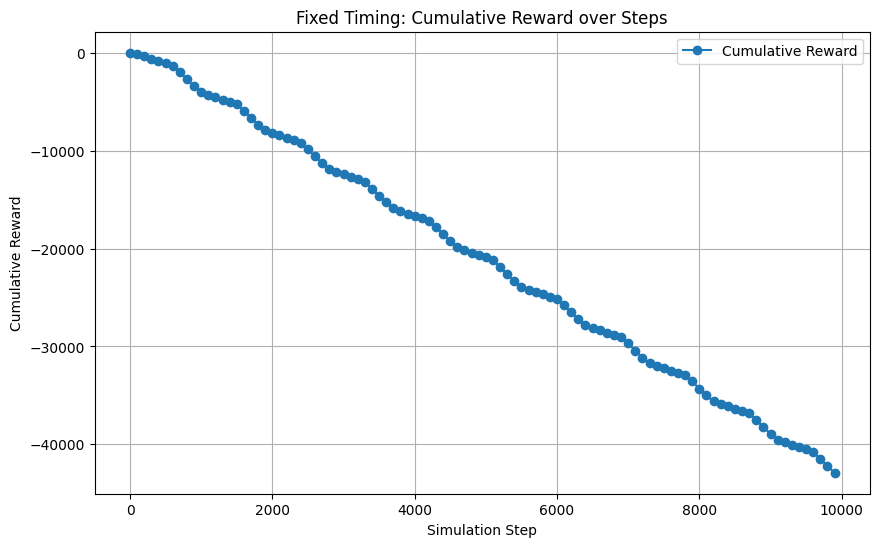

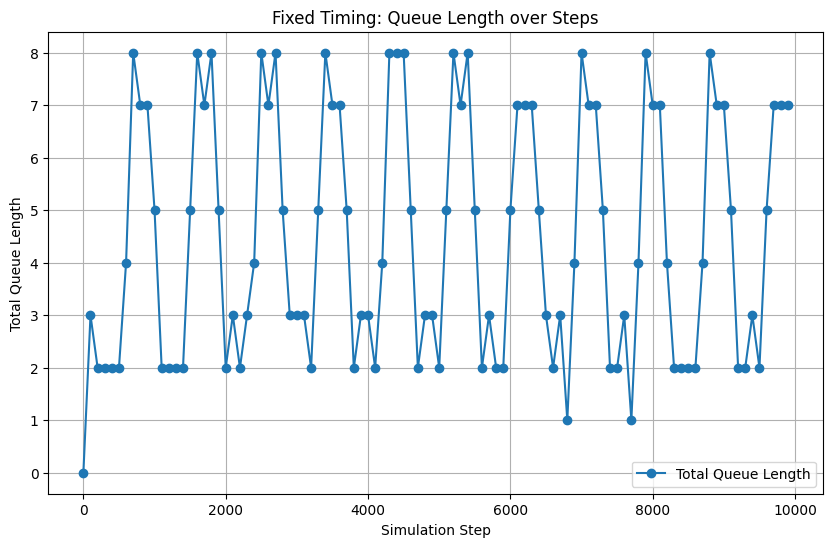

In [1]:
# Step 1: Add modules to provide access to specific libraries and functions
import os
import sys
import random
import numpy as np
import matplotlib.pyplot as plt


# Step 2: Establish path to SUMO (SUMO_HOME)
if 'SUMO_HOME' in os.environ:
    tools = os.path.join(os.environ['SUMO_HOME'], 'tools')
    sys.path.append(tools)
else:
    sys.exit("Please declare environment variable 'SUMO_HOME'")


# Step 3: Add TraCI module
import traci


# Step 4: Define SUMO configuration
Sumo_config = [
    'sumo-gui',
    '-c', 'RL.sumocfg',
    '--step-length', '0.10',
    '--delay', '1000',
    '--lateral-resolution', '0'
]


# Step 5: Open connection between SUMO and TraCI
traci.start(Sumo_config)
traci.gui.setSchema("View #0", "real world")


# -------------------------
# Step 6: Define Variables
# -------------------------

# Variables for RL State (queue lengths from detectors and current phase)
q_EB_0 = 0
q_EB_1 = 0
q_EB_2 = 0

q_SB_0 = 0
q_SB_1 = 0
q_SB_2 = 0

current_phase = 0


# ---- Reinforcement Learning Hyperparameters ----
TOTAL_STEPS = 10000

ALPHA = 0.1
GAMMA = 0.9
EPSILON = 0.0

ACTIONS = [0, 1]  # 0 = keep phase, 1 = switch phase


# Q-table dictionary
# Key = state tuple
# Value = NumPy array of Q-values for each action
Q_table = {}


# ---- Additional Stability Parameters ----
MIN_GREEN_STEPS = 0
last_switch_step = -MIN_GREEN_STEPS


# -------------------------
# Step 7: Define Functions
# -------------------------

def get_max_Q_value_of_state(s):
    # Objective Function 1
    if s not in Q_table:
        Q_table[s] = np.zeros(len(ACTIONS))

    return np.max(Q_table[s])


def get_reward(state):
    # Constraint 2
    """
    Simple reward function:
    Negative of total queue length to encourage shorter queues.
    """

    total_queue = sum(state[:-1])  # Exclude current_phase
    reward = -float(total_queue)

    return reward


def get_state():
    # Constraints 3 and 4

    global q_EB_0, q_EB_1, q_EB_2
    global q_SB_0, q_SB_1, q_SB_2
    global current_phase

    # ---------------------------------
    # Detector IDs for Node1-2-EB
    # ---------------------------------
    detector_Node1_2_EB_0 = "Node1-2-EB-0"
    detector_Node1_2_EB_1 = "Node1-2-EB-1"
    detector_Node1_2_EB_2 = "Node1-2-EB-2"

    # ---------------------------------
    # Detector IDs for Node1-2-SB
    # ---------------------------------
    detector_Node1_2_SB_0 = "Node1-2-SB-0"
    detector_Node1_2_SB_1 = "Node1-2-SB-1"
    detector_Node1_2_SB_2 = "Node1-2-SB-2"

    # Traffic light ID
    traffic_light_id = "Node2"

    # ---------------------------------
    # Get queue lengths from detectors
    # ---------------------------------
    q_EB_0 = get_queue_length(detector_Node1_2_EB_0)
    q_EB_1 = get_queue_length(detector_Node1_2_EB_1)
    q_EB_2 = get_queue_length(detector_Node1_2_EB_2)

    q_SB_0 = get_queue_length(detector_Node1_2_SB_0)
    q_SB_1 = get_queue_length(detector_Node1_2_SB_1)
    q_SB_2 = get_queue_length(detector_Node1_2_SB_2)

    # ---------------------------------
    # Get current traffic light phase
    # ---------------------------------
    current_phase = get_current_phase(traffic_light_id)

    return (
        q_EB_0,
        q_EB_1,
        q_EB_2,
        q_SB_0,
        q_SB_1,
        q_SB_2,
        current_phase
    )


def apply_action(action, tls_id="Node2"):
    # Constraint 5

    """
    Executes the chosen action on the traffic light, combining:
      - Minimum Green Time check
      - Switching to the next phase if allowed

    Constraint #5:
    Ensure at least MIN_GREEN_STEPS pass before switching again.
    """

    global last_switch_step

    if action == 0:
        # Do nothing (keep current phase)
        return

    elif action == 1:

        # Check minimum green time before switching
        if current_simulation_step - last_switch_step >= MIN_GREEN_STEPS:

            program = traci.trafficlight.getAllProgramLogics(tls_id)[0]
            num_phases = len(program.phases)

            next_phase = (get_current_phase(tls_id) + 1) % num_phases

            traci.trafficlight.setPhase(tls_id, next_phase)

            last_switch_step = current_simulation_step


def update_Q_table(old_state, action, reward, new_state):
    # Constraint 6

    if old_state not in Q_table:
        Q_table[old_state] = np.zeros(len(ACTIONS))

    # 1. Predict current Q-value for the old state
    old_q = Q_table[old_state][action]

    # 2. Get maximum future Q-value for the new state
    best_future_q = get_max_Q_value_of_state(new_state)

    # 3. Update Q-value using Q-learning
    Q_table[old_state][action] = (
        old_q
        + ALPHA * (reward + GAMMA * best_future_q - old_q)
    )


def get_action_from_policy(state):
    # Constraint 7

    if random.random() < EPSILON:
        return random.choice(ACTIONS)

    else:
        if state not in Q_table:
            Q_table[state] = np.zeros(len(ACTIONS))

        return 0


def get_queue_length(detector_id):
    # Constraint 8
    return traci.lanearea.getLastStepVehicleNumber(detector_id)


def get_current_phase(tls_id):
    # Constraint 8
    return traci.trafficlight.getPhase(tls_id)


# -------------------------
# Step 8: Fully Online Continuous Learning Loop
# -------------------------

# Lists to record data for plotting
step_history = []
reward_history = []
queue_history = []

cumulative_reward = 0.0


print("\n=== Starting Fully Online Continuous Learning ===")


for step in range(TOTAL_STEPS):

    current_simulation_step = step

    # Get current state
    state = get_state()

    # -------------------------
    # RL actions (currently disabled)
    # -------------------------
    # action = get_action_from_policy(state)
    # apply_action(action)

    # Advance simulation by one step
    traci.simulationStep()

    # Get new state
    new_state = get_state()

    # Calculate reward
    reward = get_reward(new_state)

    cumulative_reward += reward

    # -------------------------
    # Q-learning update (currently disabled)
    # -------------------------
    # update_Q_table(state, action, reward, new_state)

    # -------------------------
    # Record data every 100 steps
    # -------------------------
    if step % 100 == 0:

        print(
            f"Step {step}, "
            f"Current_State: {state}, "
            f"New_State: {new_state}, "
            f"Reward: {reward:.2f}, "
            f"Cumulative Reward: {cumulative_reward:.2f}"
        )

        step_history.append(step)

        reward_history.append(cumulative_reward)

        queue_history.append(sum(new_state[:-1]))

        print("Current Q-table:")

        for st, qvals in Q_table.items():
            print(f"  {st} -> {qvals}")


# -------------------------
# Step 9: Close connection between SUMO and TraCI
# -------------------------

traci.close()


# -------------------------
# Print Final Q-table Information
# -------------------------

print(
    "\nOnline Training completed. "
    "Final Q-table size:",
    len(Q_table)
)

for st, actions in Q_table.items():
    print("State:", st, "-> Q-values:", actions)


# -------------------------
# Step 10: Visualization of Results
# -------------------------

# Plot Cumulative Reward over Simulation Steps
plt.figure(figsize=(10, 6))

plt.plot(
    step_history,
    reward_history,
    marker='o',
    linestyle='-',
    label="Cumulative Reward"
)

plt.xlabel("Simulation Step")
plt.ylabel("Cumulative Reward")
plt.title("Fixed Timing: Cumulative Reward over Steps")

plt.legend()
plt.grid(True)
plt.show()


# Plot Total Queue Length over Simulation Steps
plt.figure(figsize=(10, 6))

plt.plot(
    step_history,
    queue_history,
    marker='o',
    linestyle='-',
    label="Total Queue Length"
)

plt.xlabel("Simulation Step")
plt.ylabel("Total Queue Length")
plt.title("Fixed Timing: Queue Length over Steps")

plt.legend()
plt.grid(True)
plt.show()